In [2]:
%load_ext autoreload
%autoreload 2

import gc
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import DataLoader
from datasets import load_dataset
import evaluate
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

from src.allocator import replace_linear_with_lplora, LpLoRAAllocator

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Connected to: {torch.cuda.get_device_name(0) if device == 'cuda' else 'CPU'}")

# Global dictionary to store all logs across different models and tasks
ALL_EXPERIMENT_LOGS = {}

Connected to: NVIDIA RTX A4000


In [3]:
from sklearn.metrics import accuracy_score, matthews_corrcoef
from scipy.stats import pearsonr

TASK_CONFIG = {
    "cola": {"keys": ("sentence", None), "metric": "matthews_correlation", "num_labels": 2, "is_reg": False, "max_len": 128},
    "mrpc": {"keys": ("sentence1", "sentence2"), "metric": "accuracy", "num_labels": 2, "is_reg": False, "max_len": 128},
    "rte":  {"keys": ("sentence1", "sentence2"), "metric": "accuracy", "num_labels": 2, "is_reg": False, "max_len": 256},
    "stsb": {"keys": ("sentence1", "sentence2"), "metric": "pearson", "num_labels": 1, "is_reg": True, "max_len": 128},
    "sst2": {"keys": ("sentence", None), "metric": "accuracy", "num_labels": 2, "is_reg": False, "max_len": 128},
}

def compute_glue_metric(task: str, preds: np.ndarray, labels: np.ndarray) -> float:
    if task == "cola":
        return float(matthews_corrcoef(labels, preds)) * 100.0
    elif task == "stsb":
        return float(pearsonr(preds, labels)[0]) * 100.0
    else:
        return float(accuracy_score(labels, preds)) * 100.0

def run_lplora_experiment(
    model_name: str = "microsoft/deberta-v3-base",
    task: str = "mrpc",
    init_r: int = 16,
    target_ratio: float = 0.5,
    p: float = 0.5,
    M: float = 10.0,
    lr: float = 5e-4,
    batch_size: int = 32,       # Effective batch size
    micro_batch_size: int = 8,  # Physical batch size on GPU (keeps VRAM < 4 GB!)
    epochs: int = 15,
    seed: int = 42,
):
    # Free any leftover VRAM before starting
    gc.collect()
    torch.cuda.empty_cache()

    run_id = f"{model_name.split('/')[-1]}_{task}_r{init_r}_ratio{target_ratio}_p{p}"
    print(f"\n{'='*75}\nStarting Run: {run_id}\n{'='*75}")

    torch.manual_seed(seed)
    np.random.seed(seed)

    cfg = TASK_CONFIG[task]
    max_len = cfg["max_len"]
    accum_steps = max(1, batch_size // micro_batch_size)

    raw_datasets = load_dataset("nyu-mll/glue", task)
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    s1_key, s2_key = cfg["keys"]
    def preprocess_fn(examples):
        texts = (examples[s1_key],) if s2_key is None else (examples[s1_key], examples[s2_key])
        res = tokenizer(*texts, truncation=True, max_length=max_len)
        res["labels"] = examples["label"]
        return res

    tokenized = raw_datasets.map(
        preprocess_fn, batched=True, remove_columns=raw_datasets["train"].column_names
    )
    collator = DataCollatorWithPadding(tokenizer)
    train_loader = DataLoader(tokenized["train"], batch_size=micro_batch_size, shuffle=True, collate_fn=collator)
    val_loader = DataLoader(tokenized["validation"], batch_size=32, shuffle=False, collate_fn=collator)

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name, num_labels=cfg["num_labels"], torch_dtype=torch.float32
    ).float()
    if model.config.pad_token_id is None:
        model.config.pad_token_id = tokenizer.pad_token_id

    for name, param in model.named_parameters():
        if not any(head_name in name for head_name in ("classifier", "pooler", "score")):
            param.requires_grad_(False)

    target_modules = ("query_proj", "key_proj", "value_proj", "query", "key", "value", "q_proj", "k_proj", "v_proj", "o_proj", "dense")
    model = replace_linear_with_lplora(model, target_modules=target_modules, r=init_r, lora_alpha=init_r * 2)
    model.to(device)

    total_opt_steps = (len(train_loader) // accum_steps) * epochs
    allocator = LpLoRAAllocator(
        model,
        total_steps=total_opt_steps,
        M=M,
        p=p,
        prune_every=max(5, total_opt_steps // 30),
        init_warmup_ratio=0.1,
        final_warmup_ratio=0.7,
        target_rank_ratio=target_ratio,
    )

    trainable_params = [param for param in model.parameters() if param.requires_grad]
    optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(total_opt_steps * 0.1), num_training_steps=total_opt_steps
    )

    epoch_history = []
    best_score = -1e9
    start_time = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        optimizer.zero_grad()

        for step_idx, batch in enumerate(train_loader, start=1):
            batch = {k: v.to(device) for k, v in batch.items()}
            if cfg["is_reg"]:
                batch["labels"] = batch["labels"].float()

            # bfloat16 autocast on float32 master weights is 100% immune to fp16 overflow and uses half the VRAM!
            with torch.amp.autocast("cuda", dtype=torch.bfloat16):
                outputs = model(**batch)
                loss = outputs.loss / accum_steps

            loss.backward()
            total_loss += loss.item() * accum_steps

            if step_idx % accum_steps == 0 or step_idx == len(train_loader):
                torch.nn.utils.clip_grad_norm_(trainable_params, 1.0)
                allocator.step()
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

        model.eval()
        all_preds, all_labels = [], []
        for batch in val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.no_grad(), torch.amp.autocast("cuda", dtype=torch.bfloat16):
                logits = model(**batch).logits
            preds = logits.squeeze(-1) if cfg["is_reg"] else torch.argmax(logits, dim=-1)
            all_preds.append(preds.float().cpu().numpy())
            all_labels.append(batch["labels"].float().cpu().numpy())

        score = compute_glue_metric(task, np.concatenate(all_preds), np.concatenate(all_labels))
        best_score = max(best_score, score)

        ranks = allocator.get_rank_summary()
        alive_ranks = sum(ranks.values())
        avg_loss = total_loss / len(train_loader)

        epoch_history.append({
            "epoch": epoch,
            "train_loss": avg_loss,
            "val_score": score,
            "best_score": best_score,
            "alive_ranks": alive_ranks,
            "total_ranks": allocator.initial_total_rank,
        })

        print(
            f"Epoch {epoch:2d}/{epochs} | Loss: {avg_loss:.4f} | "
            f"Val {cfg['metric']}: {score:.2f}% (Best: {best_score:.2f}%) | "
            f"Ranks: {alive_ranks}/{allocator.initial_total_rank}"
        )

    final_layer_ranks = allocator.get_rank_summary()
    elapsed = time.time() - start_time

    ALL_EXPERIMENT_LOGS[run_id] = {
        "model_name": model_name,
        "task": task,
        "metric_name": cfg["metric"],
        "best_score": best_score,
        "final_alive_ranks": sum(final_layer_ranks.values()),
        "initial_total_rank": allocator.initial_total_rank,
        "elapsed_sec": elapsed,
        "history": pd.DataFrame(epoch_history),
        "layer_ranks": final_layer_ranks,
    }

    del model, optimizer, scheduler, allocator, train_loader, val_loader
    gc.collect()
    torch.cuda.empty_cache()

    return run_id

In [3]:
# 1. Run DeBERTaV3-base on MRPC and RTE (from Table 1 of the paper)
run_lplora_experiment(model_name="microsoft/deberta-v3-base", task="mrpc", init_r=16, target_ratio=0.5, epochs=10, lr=8e-4)



Starting Run: deberta-v3-base_mrpc_r16_ratio0.5_p0.5


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
/home/prit/lp-lora/.venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Epoch  1/10 | Loss: 0.5278 | Val accuracy: 86.03% (Best: 86.03%) | Ranks: 1152/1152
Epoch  2/10 | Loss: 0.3100 | Val accuracy: 88.24% (Best: 88.24%) | Ranks: 914/1152
Epoch  3/10 | Loss: 0.1826 | Val accuracy: 90.93% (Best: 90.93%) | Ranks: 751/1152
Epoch  4/10 | Loss: 0.1168 | Val accuracy: 89.46% (Best: 90.93%) | Ranks: 652/1152
Epoch  5/10 | Loss: 0.0544 | Val accuracy: 90.20% (Best: 90.93%) | Ranks: 600/1152
Epoch  6/10 | Loss: 0.0350 | Val accuracy: 89.46% (Best: 90.93%) | Ranks: 580/1152
Epoch  7/10 | Loss: 0.0231 | Val accuracy: 90.69% (Best: 90.93%) | Ranks: 577/1152
Epoch  8/10 | Loss: 0.0135 | Val accuracy: 90.69% (Best: 90.93%) | Ranks: 577/1152
Epoch  9/10 | Loss: 0.0092 | Val accuracy: 90.93% (Best: 90.93%) | Ranks: 577/1152
Epoch 10/10 | Loss: 0.0046 | Val accuracy: 89.95% (Best: 90.93%) | Ranks: 577/1152


{'model_name': 'microsoft/deberta-v3-base',
 'task': 'mrpc',
 'metric_name': 'accuracy',
 'best_score': 90.93137254901961,
 'final_alive_ranks': 577,
 'initial_total_rank': 1152,
 'elapsed_sec': 283.7415838241577,
 'history':    epoch  train_loss  val_score  best_score  alive_ranks  total_ranks
 0      1    0.527797  86.029412   86.029412         1152         1152
 1      2    0.309989  88.235294   88.235294          914         1152
 2      3    0.182577  90.931373   90.931373          751         1152
 3      4    0.116769  89.460784   90.931373          652         1152
 4      5    0.054421  90.196078   90.931373          600         1152
 5      6    0.035035  89.460784   90.931373          580         1152
 6      7    0.023063  90.686275   90.931373          577         1152
 7      8    0.013518  90.686275   90.931373          577         1152
 8      9    0.009209  90.931373   90.931373          577         1152
 9     10    0.004600  89.950980   90.931373          577        

In [3]:
run_lplora_experiment(model_name="microsoft/deberta-v3-base", task="rte",  init_r=16, target_ratio=0.5, epochs=10, lr=8e-4)



Starting Run: deberta-v3-base_rte_r16_ratio0.5_p0.5


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
/home/prit/lp-lora/.venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.den

Epoch  1/10 | Loss: 0.6587 | Val accuracy: 81.59% (Best: 81.59%) | Ranks: 1152/1152
Epoch  2/10 | Loss: 0.4475 | Val accuracy: 85.20% (Best: 85.20%) | Ranks: 910/1152
Epoch  3/10 | Loss: 0.2336 | Val accuracy: 91.70% (Best: 91.70%) | Ranks: 748/1152
Epoch  4/10 | Loss: 0.1295 | Val accuracy: 87.36% (Best: 91.70%) | Ranks: 649/1152
Epoch  5/10 | Loss: 0.0752 | Val accuracy: 89.17% (Best: 91.70%) | Ranks: 598/1152
Epoch  6/10 | Loss: 0.0425 | Val accuracy: 89.17% (Best: 91.70%) | Ranks: 580/1152
Epoch  7/10 | Loss: 0.0161 | Val accuracy: 88.45% (Best: 91.70%) | Ranks: 577/1152
Epoch  8/10 | Loss: 0.0152 | Val accuracy: 87.00% (Best: 91.70%) | Ranks: 577/1152
Epoch  9/10 | Loss: 0.0123 | Val accuracy: 87.00% (Best: 91.70%) | Ranks: 577/1152
Epoch 10/10 | Loss: 0.0084 | Val accuracy: 87.73% (Best: 91.70%) | Ranks: 577/1152


'deberta-v3-base_rte_r16_ratio0.5_p0.5'

In [4]:

# 2. Compare against a second model architecture (e.g., RoBERTa-base) on MRPC
run_lplora_experiment(model_name="roberta-base", task="mrpc", init_r=16, target_ratio=0.5, epochs=10, lr=5e-4)



Starting Run: roberta-base_mrpc_r16_ratio0.5_p0.5


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch  1/10 | Loss: 0.5962 | Val accuracy: 81.37% (Best: 81.37%) | Ranks: 1152/1152
Epoch  2/10 | Loss: 0.4046 | Val accuracy: 82.35% (Best: 82.35%) | Ranks: 910/1152
Epoch  3/10 | Loss: 0.2880 | Val accuracy: 87.75% (Best: 87.75%) | Ranks: 748/1152
Epoch  4/10 | Loss: 0.1953 | Val accuracy: 88.97% (Best: 88.97%) | Ranks: 649/1152
Epoch  5/10 | Loss: 0.1206 | Val accuracy: 88.24% (Best: 88.97%) | Ranks: 598/1152
Epoch  6/10 | Loss: 0.0871 | Val accuracy: 88.73% (Best: 88.97%) | Ranks: 580/1152
Epoch  7/10 | Loss: 0.0578 | Val accuracy: 88.24% (Best: 88.97%) | Ranks: 577/1152
Epoch  8/10 | Loss: 0.0392 | Val accuracy: 89.46% (Best: 89.46%) | Ranks: 577/1152
Epoch  9/10 | Loss: 0.0258 | Val accuracy: 89.46% (Best: 89.46%) | Ranks: 577/1152
Epoch 10/10 | Loss: 0.0183 | Val accuracy: 88.73% (Best: 89.46%) | Ranks: 577/1152


'roberta-base_mrpc_r16_ratio0.5_p0.5'

In [4]:

# Display Master Comparison Table
summary_rows = []
for run_id, data in ALL_EXPERIMENT_LOGS.items():
    summary_rows.append({
        "Run ID": run_id,
        "Model": data["model_name"],
        "Task": data["task"].upper(),
        "Metric": data["metric_name"],
        "Best Val Score (%)": round(data["best_score"], 2),
        "Final Ranks": f"{data['final_alive_ranks']} / {data['initial_total_rank']}",
        "Time (s)": round(data["elapsed_sec"], 1),
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

""


In [5]:
# --- PART A: Complete all 4 GLUE tasks from Table 1 of the paper (DeBERTaV3-base) ---
for task_name in ["mrpc", "rte", "cola", "stsb"]:
    run_id = f"deberta-v3-base_{task_name}_r16_ratio0.5_p0.5"
    if run_id not in ALL_EXPERIMENT_LOGS:
        run_lplora_experiment(
            model_name="microsoft/deberta-v3-base",
            task=task_name,
            init_r=16,
            target_ratio=0.5,  # Prunes from 1152 -> 576 active ranks
            p=0.5,
            epochs=10,
            lr=5e-4,
        )

# --- PART B: Standard Uniform LoRA Baseline (Exact Same Parameter Budget: r=8, No Pruning!) ---
# Setting init_r=8 and target_ratio=1.0 uses 576 total ranks uniformly across all layers.
for task_name in ["mrpc", "rte"]:
    run_lplora_experiment(
        model_name="microsoft/deberta-v3-base",
        task=task_name,
        init_r=8,
        target_ratio=1.0,  # 1.0 = No pruning (Standard Uniform LoRA with r=8 -> 576 ranks)
        p=0.5,
        epochs=10,
        lr=5e-4,
    )


Starting Run: deberta-v3-base_mrpc_r16_ratio0.5_p0.5


Map:   0%|          | 0/3668 [00:00<?, ? examples/s]

Map:   0%|          | 0/408 [00:00<?, ? examples/s]

Map:   0%|          | 0/1725 [00:00<?, ? examples/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
/home/prit/lp-lora/.venv/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


...

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Epoch  1/10 | Loss: 0.5813 | Val accuracy: 85.29% (Best: 85.29%) | Ranks: 576/576
Epoch  2/10 | Loss: 0.3495 | Val accuracy: 88.97% (Best: 88.97%) | Ranks: 576/576
Epoch  3/10 | Loss: 0.2174 | Val accuracy: 88.24% (Best: 88.97%) | Ranks: 576/576
Epoch  4/10 | Loss: 0.1387 | Val accuracy: 91.91% (Best: 91.91%) | Ranks: 576/576
Epoch  5/10 | Loss: 0.0772 | Val accuracy: 91.91% (Best: 91.91%) | Ranks: 576/576
Epoch  6/10 | Loss: 0.0428 | Val accuracy: 91.91% (Best: 91.91%) | Ranks: 576/576
Epoch  7/10 | Loss: 0.0343 | Val accuracy: 90.20% (Best: 91.91%) | Ranks: 576/576
Epoch  8/10 | Loss: 0.0208 | Val accuracy: 91.42% (Best: 91.91%) | Ranks: 576/576
Epoch  9/10 | Loss: 0.0097 | Val accuracy: 91.18% (Best: 91.91%) | Ranks: 576/576
Epoch 10/10 | Loss: 0.0076 | Val accuracy: 91.91% (Best: 91.91%) | Ranks: 576/576

Starting Run: deberta-v3-base_rte_r8_ratio1.0_p0.5


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Epoch  1/10 | Loss: 0.6881 | Val accuracy: 77.98% (Best: 77.98%) | Ranks: 576/576
Epoch  2/10 | Loss: 0.3985 | Val accuracy: 83.03% (Best: 83.03%) | Ranks: 576/576
Epoch  3/10 | Loss: 0.2132 | Val accuracy: 85.20% (Best: 85.20%) | Ranks: 576/576
Epoch  4/10 | Loss: 0.1195 | Val accuracy: 83.75% (Best: 85.20%) | Ranks: 576/576
Epoch  5/10 | Loss: 0.0815 | Val accuracy: 83.75% (Best: 85.20%) | Ranks: 576/576
Epoch  6/10 | Loss: 0.0269 | Val accuracy: 85.92% (Best: 85.92%) | Ranks: 576/576
Epoch  7/10 | Loss: 0.0388 | Val accuracy: 85.56% (Best: 85.92%) | Ranks: 576/576
Epoch  8/10 | Loss: 0.0204 | Val accuracy: 85.56% (Best: 85.92%) | Ranks: 576/576
Epoch  9/10 | Loss: 0.0191 | Val accuracy: 87.00% (Best: 87.00%) | Ranks: 576/576
Epoch 10/10 | Loss: 0.0146 | Val accuracy: 87.00% (Best: 87.00%) | Ranks: 576/576


In [6]:
# Test how changing the non-convex exponent p (0 < p < 1) affects accuracy and rank distribution
for p_val in [0.2, 0.5, 0.8]:
    run_id = f"deberta-v3-base_mrpc_r16_ratio0.5_p{p_val}"
    if run_id not in ALL_EXPERIMENT_LOGS:
        run_lplora_experiment(
            model_name="microsoft/deberta-v3-base",
            task="mrpc",
            init_r=16,
            target_ratio=0.5,
            p=p_val,
            epochs=10,
            lr=5e-4,
        )

# Save all experiment results to CSV so you have them backed up for your report!
summary_rows = []
for run_id, data in ALL_EXPERIMENT_LOGS.items():
    method = "Standard LoRA (Uniform r=8)" if data["initial_total_rank"] == 576 else f"lp-LoRA (p={run_id.split('_p')[-1]})"
    summary_rows.append({
        "Run ID": run_id,
        "Method": method,
        "Model": data["model_name"].split("/")[-1],
        "Task": data["task"].upper(),
        "Metric": data["metric_name"],
        "Best Val Score (%)": round(data["best_score"], 2),
        "Active / Initial Ranks": f"{data['final_alive_ranks']} / {data['initial_total_rank']}",
        "Time (s)": round(data["elapsed_sec"], 1),
    })

results_df = pd.DataFrame(summary_rows)
results_df.to_csv("lplora_project_results.csv", index=False)
display(results_df)


Starting Run: deberta-v3-base_mrpc_r16_ratio0.5_p0.2


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Epoch  1/10 | Loss: 0.5654 | Val accuracy: 80.88% (Best: 80.88%) | Ranks: 1152/1152
Epoch  2/10 | Loss: 0.3212 | Val accuracy: 91.42% (Best: 91.42%) | Ranks: 910/1152
Epoch  3/10 | Loss: 0.1903 | Val accuracy: 88.48% (Best: 91.42%) | Ranks: 748/1152
Epoch  4/10 | Loss: 0.1120 | Val accuracy: 90.93% (Best: 91.42%) | Ranks: 649/1152
Epoch  5/10 | Loss: 0.0676 | Val accuracy: 92.16% (Best: 92.16%) | Ranks: 598/1152
Epoch  6/10 | Loss: 0.0333 | Val accuracy: 92.16% (Best: 92.16%) | Ranks: 580/1152
Epoch  7/10 | Loss: 0.0215 | Val accuracy: 91.18% (Best: 92.16%) | Ranks: 577/1152
Epoch  8/10 | Loss: 0.0168 | Val accuracy: 90.69% (Best: 92.16%) | Ranks: 577/1152
Epoch  9/10 | Loss: 0.0128 | Val accuracy: 91.91% (Best: 92.16%) | Ranks: 577/1152
Epoch 10/10 | Loss: 0.0061 | Val accuracy: 91.42% (Best: 92.16%) | Ranks: 577/1152

Starting Run: deberta-v3-base_mrpc_r16_ratio0.5_p0.8


Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
classifier.weight                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier

Epoch  1/10 | Loss: 0.5654 | Val accuracy: 80.88% (Best: 80.88%) | Ranks: 1152/1152
Epoch  2/10 | Loss: 0.3211 | Val accuracy: 91.18% (Best: 91.18%) | Ranks: 910/1152
Epoch  3/10 | Loss: 0.1920 | Val accuracy: 88.97% (Best: 91.18%) | Ranks: 748/1152
Epoch  4/10 | Loss: 0.1114 | Val accuracy: 91.67% (Best: 91.67%) | Ranks: 649/1152
Epoch  5/10 | Loss: 0.0642 | Val accuracy: 92.40% (Best: 92.40%) | Ranks: 598/1152
Epoch  6/10 | Loss: 0.0374 | Val accuracy: 91.67% (Best: 92.40%) | Ranks: 580/1152
Epoch  7/10 | Loss: 0.0258 | Val accuracy: 91.18% (Best: 92.40%) | Ranks: 577/1152
Epoch  8/10 | Loss: 0.0181 | Val accuracy: 91.91% (Best: 92.40%) | Ranks: 577/1152
Epoch  9/10 | Loss: 0.0133 | Val accuracy: 91.42% (Best: 92.40%) | Ranks: 577/1152
Epoch 10/10 | Loss: 0.0076 | Val accuracy: 91.91% (Best: 92.40%) | Ranks: 577/1152


,Run ID,Method,Model,Task,Metric,Best Val Score (%),Active / Initial Ranks,Time (s)
0,deberta-v3-base_mrpc_r16_ratio0.5_p0.5,lp-LoRA (p=0.5),deberta-v3-base,MRPC,accuracy,92.89,577 / 1152,189.3
1,deberta-v3-base_rte_r16_ratio0.5_p0.5,lp-LoRA (p=0.5),deberta-v3-base,RTE,accuracy,89.17,577 / 1152,219.1
2,deberta-v3-base_cola_r16_ratio0.5_p0.5,lp-LoRA (p=0.5),deberta-v3-base,COLA,matthews_correlation,69.50,577 / 1152,354.6
3,deberta-v3-base_stsb_r16_ratio0.5_p0.5,lp-LoRA (p=0.5),deberta-v3-base,STSB,pearson,91.52,577 / 1152,265.1
4,deberta-v3-base_mrpc_r8_ratio1.0_p0.5,Standard LoRA (Uniform r=8),deberta-v3-base,MRPC,accuracy,91.91,576 / 576,187.3
5,deberta-v3-base_rte_r8_ratio1.0_p0.5,Standard LoRA (Uniform r=8),deberta-v3-base,RTE,accuracy,87.00,576 / 576,218.5
6,deberta-v3-base_mrpc_r16_ratio0.5_p0.2,lp-LoRA (p=0.2),deberta-v3-base,MRPC,accuracy,92.16,577 / 1152,188.8
7,deberta-v3-base_mrpc_r16_ratio0.5_p0.8,lp-LoRA (p=0.8),deberta-v3-base,MRPC,accuracy,92.40,577 / 1152,189.0


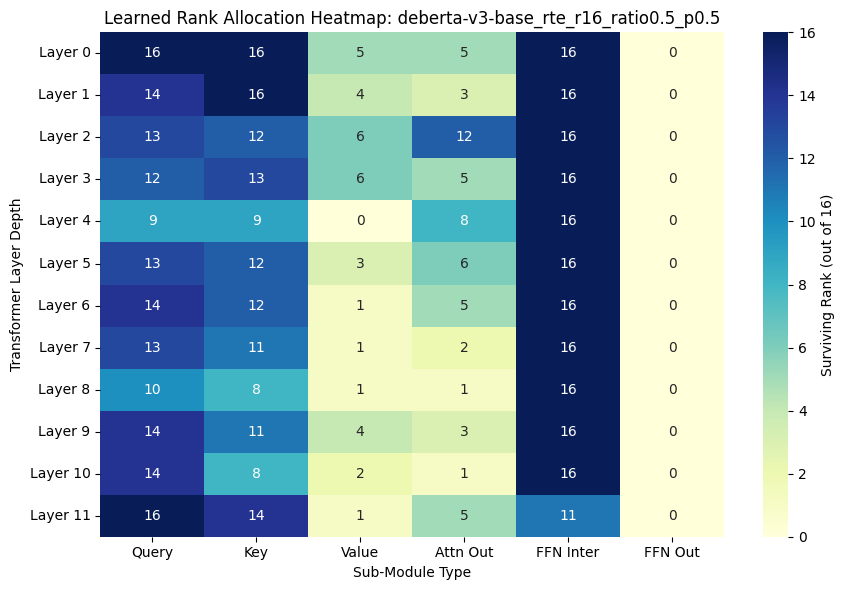

In [7]:
def plot_layer_module_heatmap(run_id: str, save_path: str = None):
    layer_ranks = ALL_EXPERIMENT_LOGS[run_id]["layer_ranks"]
    
    # Organize into a [12 layers x 6 module types] matrix
    module_types = [
        ("Query", "attention.self.query_proj"),
        ("Key", "attention.self.key_proj"),
        ("Value", "attention.self.value_proj"),
        ("Attn Out", "attention.output.dense"),
        ("FFN Inter", "intermediate.dense"),
        ("FFN Out", "output.dense"),
    ]
    
    grid = np.zeros((12, len(module_types)), dtype=int)
    for layer_idx in range(12):
        for col_idx, (_, suffix) in enumerate(module_types):
            key = f"deberta.encoder.layer.{layer_idx}.{suffix}"
            if key in layer_ranks:
                grid[layer_idx, col_idx] = layer_ranks[key]

    plt.figure(figsize=(9, 6))
    sns.heatmap(
        grid,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        vmin=0,
        vmax=16,
        xticklabels=[m[0] for m in module_types],
        yticklabels=[f"Layer {i}" for i in range(12)],
        cbar_kws={"label": "Surviving Rank (out of 16)"},
    )
    plt.title(f"Learned Rank Allocation Heatmap: {run_id}")
    plt.ylabel("Transformer Layer Depth")
    plt.xlabel("Sub-Module Type")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300)
    plt.show()

# Generate and save the heatmap for your RTE run!
plot_layer_module_heatmap("deberta-v3-base_rte_r16_ratio0.5_p0.5", save_path="rte_rank_heatmap.png")

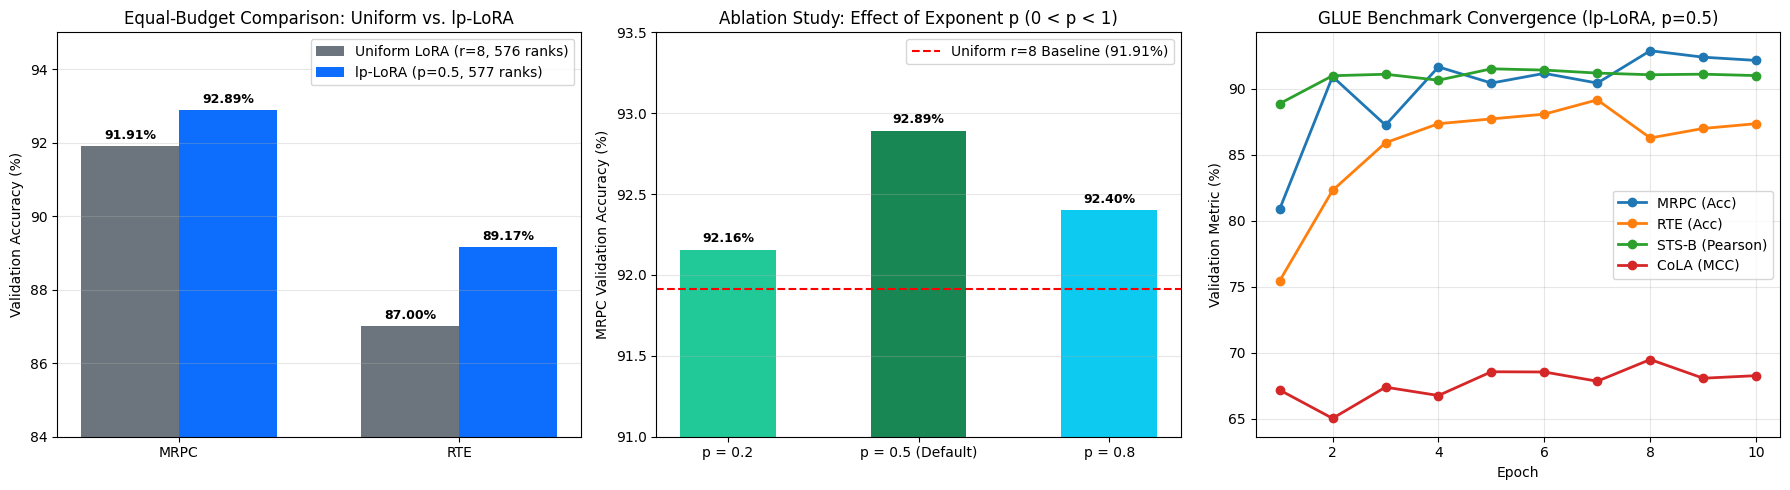

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Baseline Comparison: Uniform LoRA (r=8) vs lp-LoRA (p=0.5) at Equal Budget (~576 ranks)
tasks = ["MRPC", "RTE"]
uniform_scores = [
    ALL_EXPERIMENT_LOGS["deberta-v3-base_mrpc_r8_ratio1.0_p0.5"]["best_score"],
    ALL_EXPERIMENT_LOGS["deberta-v3-base_rte_r8_ratio1.0_p0.5"]["best_score"],
]
lplora_scores = [
    ALL_EXPERIMENT_LOGS["deberta-v3-base_mrpc_r16_ratio0.5_p0.5"]["best_score"],
    ALL_EXPERIMENT_LOGS["deberta-v3-base_rte_r16_ratio0.5_p0.5"]["best_score"],
]

x = np.arange(len(tasks))
width = 0.35
rects1 = axes[0].bar(x - width/2, uniform_scores, width, label="Uniform LoRA (r=8, 576 ranks)", color="#6c757d")
rects2 = axes[0].bar(x + width/2, lplora_scores, width, label="lp-LoRA (p=0.5, 577 ranks)", color="#0d6efd")
axes[0].set_ylim(84, 95)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tasks)
axes[0].set_ylabel("Validation Accuracy (%)")
axes[0].set_title("Equal-Budget Comparison: Uniform vs. lp-LoRA")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)
for rect in rects1 + rects2:
    h = rect.get_height()
    axes[0].annotate(f"{h:.2f}%", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

# 2. Ablation on Sparsity Exponent p in {0.2, 0.5, 0.8} on MRPC
p_vals = ["p = 0.2", "p = 0.5 (Default)", "p = 0.8"]
p_scores = [
    ALL_EXPERIMENT_LOGS["deberta-v3-base_mrpc_r16_ratio0.5_p0.2"]["best_score"],
    ALL_EXPERIMENT_LOGS["deberta-v3-base_mrpc_r16_ratio0.5_p0.5"]["best_score"],
    ALL_EXPERIMENT_LOGS["deberta-v3-base_mrpc_r16_ratio0.5_p0.8"]["best_score"],
]
bars = axes[1].bar(p_vals, p_scores, color=["#20c997", "#198754", "#0dcaf0"], width=0.5)
axes[1].axhline(y=uniform_scores[0], color="red", linestyle="--", label=f"Uniform r=8 Baseline ({uniform_scores[0]:.2f}%)")
axes[1].set_ylim(91.0, 93.5)
axes[1].set_ylabel("MRPC Validation Accuracy (%)")
axes[1].set_title("Ablation Study: Effect of Exponent p (0 < p < 1)")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)
for bar in bars:
    h = bar.get_height()
    axes[1].annotate(f"{h:.2f}%", xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

# 3. Validation Curves Across All 4 GLUE Tasks
for task_key, label_str in [("mrpc", "MRPC (Acc)"), ("rte", "RTE (Acc)"), ("stsb", "STS-B (Pearson)"), ("cola", "CoLA (MCC)")]:
    run_key = f"deberta-v3-base_{task_key}_r16_ratio0.5_p0.5"
    df_hist = ALL_EXPERIMENT_LOGS[run_key]["history"]
    axes[2].plot(df_hist["epoch"], df_hist["val_score"], marker="o", linewidth=2, label=label_str)

axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Validation Metric (%)")
axes[2].set_title("GLUE Benchmark Convergence (lp-LoRA, p=0.5)")
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("lplora_ablation_and_results.png", dpi=300)
plt.show()

In [9]:
import pickle
with open("all_experiment_logs.pkl", "wb") as f:
    pickle.dump(ALL_EXPERIMENT_LOGS, f)
print("Saved all experiment logs to all_experiment_logs.pkl!")

Saved all experiment logs to all_experiment_logs.pkl!
